# 5 · Scenarios — What Happens When Spend Changes

**Brief Question:** Where should we increase or decrease spend to acquire new customers at a marginal cost below **£40** per additional customer? We start from the average daily spend in **September 2026** and look **30 days** ahead under similar trading conditions.

**What is covered in Part 1:**
0. Setup and loading of the model from `4_modeling` (`mmm_final.nc`) along with files from `2`/`3`.
1. Input data validation: checking whether the model observed the exact scales we assume.
2. Custom contribution engine (adstock → saturation → β), **validated against the library** to machine precision on the same posterior draws.
3. Brief checks that can be performed right away: plan vs. itself = 0, manual calculation for a single channel.

**Part 2 (below):** Five spending plans plus an optimised reallocation, per-channel finite-window marginal CAC, response curves, per-channel sensitivity with diagnostics, a generated decision table, and a client testing plan (below).

> This notebook is designed for Google Colab. Make sure `2_data_prep`, `3_tuning` (optional), and `4_modeling` have been executed beforehand — otherwise `mmm_final.nc` will not exist.

In [1]:
import os, sys
from pathlib import Path
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- Colab ---
#PROJECT_DIR = "/content/drive/MyDrive/digis"
#  local ---
PROJECT_DIR = "."

if IN_COLAB:
    drive.mount("/content/drive")
root = Path(PROJECT_DIR).resolve()
if not (root / "notebooks").exists() and (root.parent / "notebooks").exists():
    root = root.parent
assert (root / "notebooks" / "common.py").exists(), (
    f"Not found {root}/notebooks/common.py.")
os.chdir(root / "notebooks"); sys.path.insert(0, str(root / "notebooks"))
print("root :", root, "| Colab:", IN_COLAB)

Mounted at /content/drive
root : /content/drive/MyDrive/digis | Colab: True


In [2]:
# Tested version: pymc-marketing 1.3.0 (same as in 03 and 04)
import importlib.util
if importlib.util.find_spec("pymc_marketing") is None:
    get_ipython().run_line_magic("pip", "install -q pymc-marketing==1.3.0")
    print("Installed. If you encounter an ImportError next, go to Runtime → Restart session and rerun the notebook.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.
Installed. If you encounter an ImportError next, go to Runtime → Restart session and rerun the notebook.


In [3]:
import json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pymc_marketing.mmm import MMM
from common import OUT_DIR, TARGET_CAC, OPTIONAL_CONTROLS
warnings.filterwarnings("ignore"); pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
SEED = 42

cfg  = json.load(open(OUT_DIR / "config.json"))
df   = pd.read_csv(OUT_DIR / "model_input.csv", parse_dates=["date"])
meta = json.load(open(OUT_DIR / "model_meta.json"))          # recorded in 04_modeling
_bp  = OUT_DIR / "best_params.json"                          # recorded in 03_tuning
PARAMS = meta["params"]                                      # параметри, з якими реально навчена збережена модель
if _bp.exists() and json.load(open(_bp))["chosen"] != PARAMS:
    print("WARNING: best_params.json відрізняється від параметрів збереженої моделі: перезапустіть 04_modeling")
print("Hyperparameters:", PARAMS, "| source:", "model_meta.json (04_modeling)")

MODEL_PATH = OUT_DIR / "mmm_final.nc"
assert MODEL_PATH.exists(), "Missing mmm_final.nc: run 04_modeling first"
mmm = MMM.load(str(MODEL_PATH))

# Extract channels and controls directly from the model rather than a hardcoded list to catch name mismatches immediately
CH = list(mmm.channel_columns)
CT = list(mmm.control_columns)
# Match the exact feature layout used to fit the saved model in Notebook 4.
COLS = ["date"] + CH + CT
# Reuse the tuned prior scale from 03_tuning (do not hardcode a second value).
BETA_SIGMA = float(PARAMS["beta_sigma"])
# L_MAX is retrieved from the model itself (the actual adstock length used during training).
# model_meta.json and PARAMS must match it; if not, we halt rather than computing with a mismatched l_max.
L_MAX = int(mmm.adstock.l_max)
K_YEARLY = int(meta["k_yearly"]); SATURATION = PARAMS["saturation"]
assert L_MAX == int(meta["l_max"]) == int(PARAMS["l_max"]), (
    f"l_max mismatch: model={L_MAX}, meta={meta['l_max']}, PARAMS={PARAMS['l_max']}. "
    "Check which l_max was used in 04 (see diagnostic cell below)")
assert type(mmm.saturation).__name__ == ("LogisticSaturation" if SATURATION == "logistic" else "HillSaturation"), (
    f"model saturation {type(mmm.saturation).__name__} ≠ PARAMS['saturation']={SATURATION}")
assert CH == cfg["channels"], f"model channels {CH} ≠ config {cfg['channels']}"
assert set(cfg["controls"]) <= set(CT), "model is missing controls from config"
assert SATURATION in ("logistic", "hill"), SATURATION
print("channels:", CH)
print("controls:", CT)
print(f"L_MAX={L_MAX}, K={K_YEARLY}, saturation={SATURATION}, beta_sigma={BETA_SIGMA:.6g}")
print("Training feature columns:", COLS)

Hyperparameters: {'k_yearly': 6, 'l_max': 21, 'saturation': 'logistic', 'beta_sigma': 0.5489779514362569, 'bf_features': 'peak+window'} | source: model_meta.json (04_modeling)
channels: ['bing', 'google', 'meta', 'pinterest']
controls: ['dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'bf_cm_peak', 'promo', 't', 'xmas_eve_day', 'new_year', 'bf_window']
L_MAX=21, K=6, saturation=logistic, beta_sigma=0.548978
Training feature columns: ['date', 'bing', 'google', 'meta', 'pinterest', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'bf_cm_peak', 'promo', 't', 'xmas_eve_day', 'new_year', 'bf_window']


### Input Data Validation Prior to Scenarios
Scenarios will not fix a flawed input file. Here, we verify three things: (a) data integrity, (b) that the model scaled the data as expected, and (c) that the baseline spend is derived from the correct period.

The model divides spend by the maximum channel value, and the target by the maximum number of new customers; therefore, these scales must equal the historical maximums. Otherwise, all estimates regarding £ per customer will be incorrect.

In [4]:
sc = mmm.get_scales_as_xarray()
TS = float(sc["target_scale"])                        # target scale (max new customers)
CS = sc["channel_scale"].sel(channel=CH).values      # individual channel scale (max spend)

checks = {
    "dates continuous without gaps/duplicates": df.date.is_unique and (df.date.diff().dropna() == pd.Timedelta(days=1)).all(),
    "no missing values (NaN)": df.isna().sum().sum() == 0,
    "channel spend ≥ 0": bool((df[CH] >= 0).all().all()),
    "t = day/n (as in 02)": bool(np.allclose(df.t, np.arange(len(df)) / len(df))),
    "channel scales = historical max": bool(np.allclose(CS, df[CH].max().values)),
    "target scale = max new customers": bool(np.isclose(TS, df.new.max())),
}
for k, v in checks.items():
    print(("OK   " if v else "FAIL ") + k)
assert all(checks.values()), "Input data or scales do not match, see FAIL above"
print(f"\nscales: target = {TS:.0f}; channels: " + ", ".join(f"{c} = {v:.0f}" for c, v in zip(CH, CS)))

OK   dates continuous without gaps/duplicates
OK   no missing values (NaN)
OK   channel spend ≥ 0
OK   t = day/n (as in 02)
OK   channel scales = historical max
OK   target scale = max new customers

scales: target = 2290; channels: bing = 1070, google = 13488, meta = 19251, pinterest = 3029


In [5]:
BASE_MONTH = cfg["baseline_month"]                   # "2026-09"
base_rows = df[df.date.dt.strftime("%Y-%m") == BASE_MONTH]
assert len(base_rows) == 30, f"{BASE_MONTH} must have 30 days, found {len(base_rows)}"

BASE = base_rows[CH].mean().values                   # baseline spend, £/day, by channel
EVENT = (df.promo > 0) | (df.bf_window == 1)         # days with discounts or BF/CM window
P95_HIST = df.loc[~EVENT, CH].quantile(0.95).values  # upper bound of "normal" spend for reallocation

summary = pd.DataFrame({
    "Sep 2026, £/day": BASE.round(0),
    "normal days: p95, £/day": P95_HIST.round(0),
    "historical max, £/day": df[CH].max().values.round(0),
    "Sep / p95": (BASE / P95_HIST).round(2),
}, index=CH)
display(summary)
print(f"Baseline budget for 30 days: £{BASE.sum()*30:,.0f} (total across 4 channels)")
print("A 'Sep / p95' ratio >1 indicates that the baseline spend is already above the channel's usual maximum.")

,"Sep 2026, £/day","normal days: p95, £/day","historical max, £/day",Sep / p95
bing,331.0,500.0,1070.0,0.66
google,2265.0,3663.0,13488.0,0.62
meta,2509.0,5405.0,19251.0,0.46
pinterest,635.0,873.0,3029.0,0.73


Baseline budget for 30 days: £172,209 (total across 4 channels)
A 'Sep / p95' ratio >1 indicates that the baseline spend is already above the channel's usual maximum.


### Custom Contribution Engine: Adstock → Saturation → β
For each channel, we compute:

1. **Adstock** (geometric decay over `l_max` days): $\text{ad}_t=\sum_{k=0}^{L-1} w_k\, x_{t-k}$, where $w_k = \alpha^k / \sum_j \alpha^j$, and $x=\text{spend}/\text{channel scale}$.
2. **Saturation:**
   - logistic: $\;\text{sat}=\dfrac{1-e^{-\lambda\,\text{ad}}}{1+e^{-\lambda\,\text{ad}}}$;
   - hill: $\;\text{sat}=\dfrac{\text{ad}^{s}}{\kappa^{s}+\text{ad}^{s}}$ (the library formulates this as $1-\kappa^s/(\kappa^s+x^s)$, which is mathematically equivalent).
3. **Contribution in customers/day** $=\beta\cdot\text{sat}\cdot \text{target\_scale}$.

Why this matters: We compute scenarios directly across parameter draws rather than relying on the optimizer API. This ensures every figure can be reproduced manually, giving us full visibility into what the model is calculating.

In [6]:
P = mmm.idata.posterior

def _draws(name):
    x = P[name].stack(s=("chain", "draw"))
    return x.transpose("s", "channel").values if "channel" in x.dims else x.values

ALPHA = _draws("adstock_alpha")                      # (S, C)
BETA  = _draws("saturation_beta")                    # (S, C)
if SATURATION == "logistic":
    LAM = _draws("saturation_lam")
else:
    SLOPE, KAPPA = _draws("saturation_slope"), _draws("saturation_kappa")
S_DRAWS = ALPHA.shape[0]
HIST = df[CH].values                                  # historical spend for carry-over
print("posterior draws:", S_DRAWS, "| saturation form:", SATURATION)

def adstock_weights(alpha):
    """(S, C) → (S, C, L): geometric weights, normalized to 1."""
    w = alpha[:, :, None] ** np.arange(L_MAX)
    return w / w.sum(-1, keepdims=True)

def media_daily(path):
    """path: (T, C) spend £/day → (S, T, C) new customers/day from media."""
    x = path / CS
    T = x.shape[0]
    w = adstock_weights(ALPHA)
    ad = np.zeros((S_DRAWS, T, len(CH)))
    for k in range(L_MAX):                            # causal convolution without np.convolve
        if k < T:
            ad[:, k:, :] += w[:, None, :, k] * x[None, :T - k, :]
    if SATURATION == "logistic":
        z = LAM[:, None, :] * ad
        sat = (1 - np.exp(-z)) / (1 + np.exp(-z))
    else:
        a = ad ** SLOPE[:, None, :]
        sat = a / (KAPPA[:, None, :] ** SLOPE[:, None, :] + a)
    return BETA[:, None, :] * sat * TS

TAIL = 14   # tail days after the plan: delayed adstock effect

def plan_media(spend, H=30, tail=TAIL):
    """Media contribution (S, C) over H plan days and the tail.
    The plan runs for H days, after which spend returns to baseline. History preceding the plan provides the carry-over."""
    path = np.vstack([HIST[-(L_MAX - 1):], np.tile(spend, (H, 1)), np.tile(BASE, (tail, 1))])
    d = media_daily(path)[:, L_MAX - 1:, :]          # drop history, keep plan days and tail
    return d[:, :H].sum(1), d[:, H:H + tail].sum(1)

posterior draws: 4000 | saturation form: logistic


#### Check 1: Our Historical Calculation Matches the Library
We take the channel contributions recorded by the library in the posterior (`channel_contribution`) and compare them against our own calculations across all 730 days and all posterior draws. The library outputs these in the target scale, so we multiply by `target_scale`.

In [7]:
cc = P["channel_contribution"].stack(s=("chain", "draw")).transpose("s", "date", "channel").values * TS
own = media_daily(HIST)                                # from zero, just like in the library
diff = np.abs(own - cc).max()
print(f"max |our calculation − library| across all days and draws: {diff:.2e} customers")
HIST_OK = diff < 1e-6
print("OK: historical calculation matches the library" if HIST_OK else "FAIL: calculation mismatch, see diagnostics below")

max |our calculation − library| across all days and draws: 5.68e-13 customers
OK: historical calculation matches the library


#### Check 2: Future 44 Days (Plan + Tail) Under the Same Draws
Forecasting the future requires control variable values for those days. We assume **similar trading conditions**: the calendar (day of week), average standard September discount, and no major events (BF, Cyber Monday, Christmas, New Year). The `t` trend is extrapolated linearly, matching how the model constructed it in `2`.

The scenario Δ between two plans **is independent** of the controls because they remain identical in both plans. Therefore, comparing our implementation with the library on future days serves as a rigorous validation test for the engine.

In [8]:
FUT_START = df.date.max() + pd.Timedelta(days=1)
EVENT_COLS = ["bf_cm_peak", "xmas_eve_day", "new_year", "holiday_low", "bf_window", "bf_day", "cm_day"]

def future_frame(n_days, spend_rows):
    """Rows for future days: calendar, controls, spend (spend_rows: (n_days, C))."""
    d = pd.DataFrame({"date": pd.date_range(FUT_START, periods=n_days, freq="D")})
    assert d.date.max() < pd.Timestamp("2026-11-20"), "window must be prior to the BF season (27.11.2026)"
    dow = d.date.dt.dayofweek
    for c in CT:
        if c.startswith("dow_"):
            d[c] = (dow == int(c.split("_")[1])).astype(int)
        elif c in EVENT_COLS:
            d[c] = 0                                      # no events during this window
        elif c == "promo":
            d[c] = float(df.loc[df.date.dt.strftime("%Y-%m") == BASE_MONTH, "promo"].mean())
        elif c == "t":
            d[c] = (len(df) + np.arange(n_days)) / len(df)
        else:
            raise KeyError(f"unknown control {c}: add a rule for future periods")
    d[CH] = spend_rows
    return d[["date"] + CH + CT]

def lib_mu(spend, H=30, tail=TAIL):
    """Library: expected customers/day (mu) over H+tail days, across all draws. Scaled by target scale."""
    rows = np.vstack([np.tile(spend, (H, 1)), np.tile(BASE, (tail, 1))])
    X = future_frame(H + tail, rows)
    pp = mmm.sample_posterior_predictive(X, extend_idata=False, combined=False,
                                         include_last_observations=True, var_names=["mu"],
                                         random_seed=SEED)["mu"]
    return pp.stack(s=("chain", "draw")).transpose("s", "date").values * TS

TEST_PLANS = {
    "baseline (0%)":         BASE,
    "all channels +10%":     BASE * 1.10,
    "all channels −10%":     BASE * 0.90,
    "Meta +20%, Google −20%": BASE * np.array([1, 0.8, 1.2, 1]),   # CH = bing, google, meta, pinterest
}

In [9]:
rows = []
base_lib = lib_mu(BASE)
base_media_in, base_media_tail = plan_media(BASE)
for name, sp in TEST_PLANS.items():
    lib = lib_mu(sp)
    eng_in, eng_tail = plan_media(sp)
    d_lib = (lib[:, :30].sum(1) - base_lib[:, :30].sum(1)) + (lib[:, 30:].sum(1) - base_lib[:, 30:].sum(1))
    d_eng = (eng_in.sum(1) + eng_tail.sum(1)) - (base_media_in.sum(1) + base_media_tail.sum(1))
    gap = np.abs(d_lib - d_eng).max()
    rows.append({"plan": name, "Δ library (mean)": round(d_lib.mean(), 2),
                 "Δ engine (mean)": round(d_eng.mean(), 2), "max discrepancy": f"{gap:.1e}"})
    assert gap < 1e-6 * max(1.0, np.abs(d_lib).max()), f"discrepancy in plan '{name}'"
display(pd.DataFrame(rows))
print("OK: across all 4 plans, engine Δ matches library Δ on the same draws (to machine precision)")

Output()

Output()

Output()

Output()

Output()

,plan,Δ library (mean),Δ engine (mean),max discrepancy
0,baseline (0%),0.00,0.00,0.0e+00
1,all channels +10%,582.43,582.43,1.3e-11
2,all channels −10%,-590.27,-590.27,1.5e-11
3,"Meta +20%, Google −20%",183.27,183.27,1.5e-11


OK: across all 4 plans, engine Δ matches library Δ on the same draws (to machine precision)


### Brief Checks, Part 1
**(a) Plan vs. Itself Equals Zero.** When comparing a spend plan against itself, the change must be exactly zero. This verifies that the engine contains no random noise or baseline shift.

**(b) Manual Single-Channel Calculation.** We take a single parameter draw and a single channel (Meta, +10%), and compute the contribution using an **explicit day-by-day loop** without any vectorised convolution. We then compare the result against the engine and the `ΔS / ΔN` estimate.

In [10]:
# (a) Plan vs. self-plan sanity check
a_in, a_tail = plan_media(BASE)
b_in, b_tail = plan_media(BASE.copy())
assert np.abs(a_in - b_in).max() == 0 and np.abs(a_tail - b_tail).max() == 0
print("(a) Plan vs. self-plan: ΔN = 0 across all draws  OK")

# (b) Manual calculation: single draw, single channel (meta), +10% spend
s0, ci = 0, CH.index("meta")
sp = BASE.copy()
sp[ci] *= 1.10


def manual_channel(path_c, s, i):
  """Explicit loop: adstock via weighted sum of days, then saturation and beta.

  Without np.convolve.
  """
  a = ALPHA[s, i]
  w = [a**k for k in range(L_MAX)]
  tot = sum(w)
  w = [x / tot for x in w]
  out = []
  for t in range(L_MAX - 1, len(path_c)):
    ad = sum(w[k] * path_c[t - k] / CS[i] for k in range(L_MAX))
    if SATURATION == "logistic":
      z = LAM[s, i] * ad
      sat = (1 - np.exp(-z)) / (1 + np.exp(-z))
    else:
      sat = ad ** SLOPE[s, i] / (
          KAPPA[s, i] ** SLOPE[s, i] + ad ** SLOPE[s, i]
      )
    out.append(BETA[s, i] * sat * TS)
  return np.array(out)


H = 30
path_base = np.concatenate([
    HIST[-(L_MAX - 1) :, ci],
    np.full(H, BASE[ci]),
    np.full(TAIL, BASE[ci]),
])
path_plus = np.concatenate([
    HIST[-(L_MAX - 1) :, ci],
    np.full(H, sp[ci]),
    np.full(TAIL, BASE[ci]),
])
man_dN = (
    manual_channel(path_plus, s0, ci)[:H].sum()
    - manual_channel(path_base, s0, ci)[:H].sum()
)

sp_full = np.vstack([np.tile(sp, (H, 1)), np.tile(BASE, (TAIL, 1))])
eng_plus = media_daily(np.vstack([HIST[-(L_MAX - 1) :], sp_full]))[
    s0, L_MAX - 1 :, ci
]
eng_base = media_daily(
    np.vstack([HIST[-(L_MAX - 1) :], np.tile(BASE, (H + TAIL, 1))])
)[s0, L_MAX - 1 :, ci]
eng_dN = eng_plus[:H].sum() - eng_base[:H].sum()

dS = (sp[ci] - BASE[ci]) * H
print(f"(b) Meta +10% for 30 days: ΔS = £{dS:,.0f}")
print(
    f"    Manual ΔN = {man_dN:.3f} | Engine ΔN = {eng_dN:.3f} | Difference ="
    f" {abs(man_dN - eng_dN):.1e}"
)
print(
    f"    iCPA (ΔS/ΔN) for this draw = £{dS / man_dN:.1f}  (Threshold:"
    f" £{TARGET_CAC})"
)
assert abs(man_dN - eng_dN) < 1e-6 * max(1, abs(man_dN))
print("OK: Manual calculation matches the media engine")

(a) Plan vs. self-plan: ΔN = 0 across all draws  OK
(b) Meta +10% for 30 days: ΔS = £7,528
    Manual ΔN = 262.905 | Engine ΔN = 262.905 | Difference = 0.0e+00
    iCPA (ΔS/ΔN) for this draw = £28.6  (Threshold: £40)
OK: Manual calculation matches the media engine


#### Check 3: analytic marginal CAC = finite difference, and one engine for every model
The closed-form steady-state marginal CAC is easy to get wrong by a constant factor (the logistic saturation is `tanh(z/2)`, so the derivative contains `sech²(lam·x/(2c))`). We therefore check it numerically for **every** channel and draw: bump the constant daily spend by ±1% through the engine and compare the slope with the formula. The `Engine` class below repeats the same adstock → saturation → β calculation for *any* fitted model, which is what the sensitivity section needs.

In [11]:
class Engine:
    """adstock → saturation → β для будь-якої навченої моделі (та сама математика, що в media_daily)."""
    def __init__(self, model, max_draws=None, seed=SEED):
        post, sca = model.idata.posterior, model.get_scales_as_xarray()
        self.ts = float(sca["target_scale"]); self.cs = sca["channel_scale"].sel(channel=CH).values
        self.L = int(model.adstock.l_max)
        self.kind = "logistic" if type(model.saturation).__name__ == "LogisticSaturation" else "hill"
        g = lambda n: post[n].stack(s=("chain", "draw")).transpose("s", "channel").values
        self.alpha, self.beta = g("adstock_alpha"), g("saturation_beta")
        self.par = (g("saturation_lam"),) if self.kind == "logistic" else (g("saturation_slope"), g("saturation_kappa"))
        if max_draws and max_draws < self.alpha.shape[0]:
            idx = np.random.default_rng(seed).choice(self.alpha.shape[0], max_draws, replace=False)
            self.alpha, self.beta, self.par = self.alpha[idx], self.beta[idx], tuple(p[idx] for p in self.par)
        self.S = self.alpha.shape[0]

    def sat(self, ad):
        if self.kind == "logistic":
            return np.tanh(self.par[0][:, None, :] * ad / 2)          # = (1-e^-z)/(1+e^-z)
        s, k = self.par[0][:, None, :], self.par[1][:, None, :]; a = ad ** s
        return a / (k ** s + a)

    def daily(self, path):                                            # (T,C) £/day → (S,T,C) клієнтів/день від медіа
        x = path / self.cs; T = len(x)
        w = self.alpha[:, :, None] ** np.arange(self.L); w = w / w.sum(-1, keepdims=True)
        ad = np.zeros((self.S, T, len(CH)))
        for k in range(self.L):
            if k < T: ad[:, k:, :] += w[:, None, :, k] * x[None, :T - k, :]
        return self.beta[:, None, :] * self.sat(ad) * self.ts

    def plan(self, spend, H=30):                                      # (S,) клієнтів від медіа за H днів плану
        path = np.vstack([HIST[-(self.L - 1):], np.tile(spend, (H, 1))])
        return self.daily(path)[:, self.L - 1:, :].sum((1, 2))

    def steady(self, x, i):                                           # клієнти/день каналу i при постійних x £/день
        path = np.tile(np.eye(len(CH))[i] * x, (self.L + 5, 1)); return self.daily(path)[:, -1, i]

    def mcac_analytic(self, x, i):                                    # замкнена форма граничного CAC, сталий режим
        u = x / self.cs[i]
        if self.kind == "logistic":
            lam = self.par[0][:, i]
            d = self.beta[:, i] * self.ts * lam / (2 * self.cs[i]) / np.cosh(lam * u / 2) ** 2
        else:
            s, k = self.par[0][:, i], self.par[1][:, i]; a = u ** s
            d = self.beta[:, i] * self.ts * s * k ** s * u ** (s - 1) / (k ** s + a) ** 2 / self.cs[i]
        return 1 / np.maximum(d, 1e-12)

ENG = Engine(mmm)
assert np.abs(ENG.daily(HIST) - media_daily(HIST)).max() < 1e-9, "Engine ≠ media_daily"
rows = []
for i, ch in enumerate(CH):
    x, h = BASE[i], 0.01 * BASE[i]
    fd = (ENG.steady(x + h, i) - ENG.steady(x - h, i)) / (2 * h)       # числова похідна через рушій
    an = 1 / ENG.mcac_analytic(x, i)                                   # аналітична похідна
    err = float(np.max(np.abs(fd / an - 1)))
    rows.append((ch, round(float(np.median(1 / an)), 2), f"{err:.1e}"))
    assert err < 1e-3, f"аналітичний граничний CAC не збігається з числовим для {ch}: {err:.2e}"
print(pd.DataFrame(rows, columns=["channel", "steady-state marginal CAC, median £", "max rel. error vs finite difference"]).to_string(index=False))
print("OK: closed-form marginal CAC matches the engine's numerical derivative for every channel and draw")

  channel  steady-state marginal CAC, median £ max rel. error vs finite difference
     bing                                10.19                             6.8e-06
   google                                42.88                             5.8e-05
     meta                                29.36                             3.0e-06
pinterest                                26.42                             3.9e-05
OK: closed-form marginal CAC matches the engine's numerical derivative for every channel and draw


### Summary of Part 1

- Input data and scales verified; baseline spend based on September 2026.
- The custom media engine is checked against the library on historical data and on future test plans.
- The plan-vs-itself and manual single-channel checks validate the scenario calculation.

Part 2 follows below with five spend plans, response curves, sensitivity analysis, a decision rule, and a client testing plan.

- Check 3: the analytic steady-state marginal CAC matches a numerical derivative of the engine for every channel and draw.

# Part 2 — Five Spend Plans, Response Curves and Client Decision

All plans use September 2026 average daily spend as the starting point and a 30-day horizon. The comparison is made on the **same posterior draws** and under identical future controls. Customer ranges below are posterior 5th–95th percentiles for expected customers, not guarantees.

For the main five plans:
1. Keep spend unchanged.
2. Increase every channel by 10%.
3. Increase every channel by 20%.
4. Reduce every channel by 10%.
5. Reallocate budget at constant total spend: transfer a modest amount from the channel with the highest posterior-median marginal CAC to the one with the lowest, subject to historical spend guardrails.

For the 30-day customer outcome, count only customers during the 30-day plan. The post-plan tail is useful for understanding carry-over, but should not be added to the 30-day customer total.

In [12]:
# Five plans. Reallocation is a transparent rule-based illustration, not an optimizer.
H = 30
base_mu_draws = lib_mu(BASE, H=H)[:, :H].sum(axis=1)
base_media_in, base_media_tail = plan_media(BASE, H=H)
base_media_30 = base_media_in.sum(axis=1)

# Steady-state marginal CAC at September spend, calculated draw-by-draw.
def marginal_cac_at_spend(spend, channel_idx):
    i = channel_idx
    x_scaled = spend / CS[i]
    if SATURATION == "logistic":
        z = LAM[:, i] * x_scaled / 2      # tanh(z/2): аргумент sech² = lam·x/(2c); без /2 CAC завищувався
        derivative = BETA[:, i] * TS * (LAM[:, i] / (2 * CS[i])) / np.cosh(z) ** 2
    else:
        a = x_scaled ** SLOPE[:, i]
        k = KAPPA[:, i] ** SLOPE[:, i]
        derivative = BETA[:, i] * TS * (SLOPE[:, i] * KAPPA[:, i] ** SLOPE[:, i]
                    * x_scaled ** (SLOPE[:, i] - 1) / (k + a) ** 2) / CS[i]
    return 1 / np.maximum(derivative, 1e-12)

mcac_medians = np.array([np.median(marginal_cac_at_spend(BASE[i], i)) for i in range(len(CH))])

# Receiver must have headroom below its non-event historical P95 spend.
# Rank eligible receivers by marginal CAC; choose the most expensive donor
# among the remaining channels. This makes the documented guardrail real.
headroom = np.maximum(P95_HIST - BASE, 0.0)
eligible_receivers = np.flatnonzero(headroom > 1e-9)
realloc = BASE.copy()
transfer = 0.0

if len(eligible_receivers):
    best_i = int(eligible_receivers[np.argmin(mcac_medians[eligible_receivers])])
    donor_candidates = [i for i in range(len(CH)) if i != best_i and BASE[i] > 0]
    if donor_candidates:
        worst_i = int(donor_candidates[np.argmax(mcac_medians[donor_candidates])])
        transfer = min(
            0.10 * BASE[worst_i],       # max 10% of donor daily spend
            0.20 * BASE[best_i],        # max 20% of receiver daily spend
            headroom[best_i],           # do not exceed normal-day P95
        )
        realloc[worst_i] -= transfer
        realloc[best_i] += transfer
else:
    best_i = worst_i = None
    print("No channel has headroom below its non-event P95; reallocation remains at baseline.")


PLANS = {
    "1. Hold baseline": BASE.copy(),
    "2. All channels +10%": BASE * 1.10,
    "3. All channels +20%": BASE * 1.20,
    "4. All channels -10%": BASE * 0.90,
    "5. Constant-budget reallocation": realloc,
}
assert np.isclose(PLANS["5. Constant-budget reallocation"].sum(), BASE.sum())
print("Marginal CAC medians at baseline:", dict(zip(CH, mcac_medians.round(1))))
if transfer > 0:
    print(f"Reallocation: £{transfer:,.0f}/day from {CH[worst_i]} to {CH[best_i]}")
else:
    print("Reallocation: no transfer (no eligible receiver/donor under the P95 guardrail).")

def summarize_plan(name, spend):
    inc, tail = plan_media(spend, H=H)
    delta_n = inc.sum(axis=1) - base_media_30
    total_customers = base_mu_draws + delta_n
    delta_budget = float((spend.sum() - BASE.sum()) * H)
    if delta_budget > 0:
        cac = delta_budget / np.maximum(delta_n, 1e-9)
        cac = np.where(delta_n > 0, cac, np.inf)
        p_under = float(np.mean(cac < TARGET_CAC))
        cac_med, cac_lo, cac_hi = np.percentile(cac[np.isfinite(cac)], [50, 5, 95]) if np.isfinite(cac).any() else (np.inf, np.inf, np.inf)
        efficiency_label = "incremental CAC"
    elif delta_budget < 0:
        saved = -delta_budget
        lost = -delta_n
        cac = saved / np.maximum(lost, 1e-9)
        cac = np.where(lost > 0, cac, np.nan)
        p_under = np.nan
        cac_med, cac_lo, cac_hi = np.nanpercentile(cac, [50, 5, 95]) if np.isfinite(cac).any() else (np.nan, np.nan, np.nan)
        efficiency_label = "saving per lost customer"
    else:
        p_under = np.nan
        cac_med = cac_lo = cac_hi = np.nan
        efficiency_label = "same-budget customer change"
    return {
        "plan": name,
        **{f"{ch} £/day": float(spend[i]) for i, ch in enumerate(CH)},
        "total budget / 30d (£)": float(spend.sum() * H),
        "Δ budget vs baseline (£)": delta_budget,
        "expected customers (median)": float(np.median(total_customers)),
        "customers P05": float(np.percentile(total_customers, 5)),
        "customers P95": float(np.percentile(total_customers, 95)),
        "Δ customers (median)": float(np.median(delta_n)),
        "Δ customers P05": float(np.percentile(delta_n, 5)),
        "Δ customers P95": float(np.percentile(delta_n, 95)),
        "incremental CAC median (£)": float(cac_med) if delta_budget > 0 else np.nan,
        "saving per lost customer median (£)": float(cac_med) if delta_budget < 0 else np.nan,
        "P(incremental CAC < £40)": p_under,
        "P(Δ customers > 0)": float(np.mean(delta_n > 0)),
    }

scenario_table = pd.DataFrame([summarize_plan(n, s) for n, s in PLANS.items()])
display(scenario_table.round(1))
print("Note: positive-spend CAC is Δ spend / Δ customers; for cuts, report savings / customers lost; reallocation has no incremental budget.")


Output()

Marginal CAC medians at baseline: {'bing': np.float64(10.2), 'google': np.float64(42.9), 'meta': np.float64(29.4), 'pinterest': np.float64(26.4)}
Reallocation: £66/day from google to bing


,plan,bing £/day,google £/day,meta £/day,pinterest £/day,total budget / 30d (£),Δ budget vs baseline (£),expected customers (median),customers P05,customers P95,Δ customers (median),Δ customers P05,Δ customers P95,incremental CAC median (£),saving per lost customer median (£),P(incremental CAC < £40),P(Δ customers > 0)
0,1. Hold baseline,331.4,2265.0,2509.4,634.5,172209.3,0.0,13655.7,13159.9,14136.8,0.0,0.0,0.0,NaN,NaN,NaN,0.0
1,2. All channels +10%,364.6,2491.4,2760.3,698.0,189430.2,17220.9,14231.8,13766.1,14687.1,575.6,505.1,648.3,29.9,NaN,1.0,1.0
2,3. All channels +20%,397.7,2717.9,3011.3,761.4,206651.2,34441.9,14800.2,14354.5,15231.4,1143.1,1003.9,1286.8,30.1,NaN,1.0,1.0
3,4. All channels -10%,298.3,2038.5,2258.5,571.1,154988.4,-17220.9,13074.1,12535.0,13590.7,-583.6,-657.9,-509.7,NaN,29.5,NaN,0.0
4,5. Constant-budget reallocation,397.7,2198.7,2509.4,634.5,172209.3,0.0,13806.8,13316.4,14275.3,147.4,71.7,216.8,NaN,NaN,NaN,1.0


Note: positive-spend CAC is Δ spend / Δ customers; for cuts, report savings / customers lost; reallocation has no incremental budget.


### Plan 5b — optimised reallocation (same total budget)
Plan 5 above is a transparent rule of thumb and is deliberately small. Here the budget split is **optimised** for expected incremental customers over the 30 days, with the same guardrails: total spend fixed, each channel within ±`MAX_SHIFT` of September, and no channel pushed above its normal-day P95 (unless September is already above it). The optimiser works on the posterior mean over a subsample of draws, so it is optimistic by construction; the result is re-evaluated on **all** draws and should be confirmed by a test before any permanent shift.

In [13]:
from scipy.optimize import minimize
MAX_SHIFT = 0.20
ENG_OPT = Engine(mmm, max_draws=500)
lo = BASE * (1 - MAX_SHIFT); hi = np.minimum(BASE * (1 + MAX_SHIFT), np.maximum(P95_HIST, BASE))
base_opt = ENG_OPT.plan(BASE)
res = minimize(lambda x: -(ENG_OPT.plan(x) - base_opt).mean(), BASE.copy(), method="SLSQP",
               bounds=list(zip(lo, hi)), constraints=[{"type": "eq", "fun": lambda x: x.sum() - BASE.sum()}],
               options={"maxiter": 80, "ftol": 1e-7})
OPT = np.clip(res.x, lo, hi); OPT = OPT * BASE.sum() / OPT.sum()
assert np.isclose(OPT.sum(), BASE.sum()) and (OPT >= lo - 1e-6).all() and (OPT <= hi + 1e-6).all()
alloc = pd.DataFrame({"baseline £/day": BASE, "optimised £/day": OPT, "change %": (OPT / BASE - 1) * 100,
                      "lower bound": lo, "upper bound": hi, "normal-day p95": P95_HIST}, index=CH).round(1)
display(alloc)
PLANS["5b. Optimised reallocation"] = OPT
tab_b = pd.DataFrame([summarize_plan("5b. Optimised reallocation", OPT)])
display(tab_b[["plan", "Δ budget vs baseline (£)", "Δ customers (median)", "Δ customers P05", "Δ customers P95", "P(Δ customers > 0)"]].round(2))
scenario_table = pd.concat([scenario_table, tab_b], ignore_index=True)
print("Optimiser converged:", res.success, "|", res.message)

,baseline £/day,optimised £/day,change %,lower bound,upper bound,normal-day p95
bing,331.4,397.7,20.0,265.2,397.7,500.0
google,2265.0,1812.0,-20.0,1812.0,2717.9,3662.6
meta,2509.4,2769.2,10.4,2007.5,3011.3,5404.5
pinterest,634.5,761.4,20.0,507.6,761.4,873.3


,plan,Δ budget vs baseline (£),Δ customers (median),Δ customers P05,Δ customers P95,P(Δ customers > 0)
0,5b. Optimised reallocation,0.0,271.7,131.88,406.35,1.0


Optimiser converged: True | Optimization terminated successfully


## Marginal CAC and response curves

The following curves show the steady-state response to constant daily spend. They are useful for locating diminishing returns, but the five-plan comparison above is the finite 30-day decision calculation with historical carry-over. A marginal CAC above £40 means the next pound is not expected to meet the target under the fitted model; it does not mean all existing spend in that channel is inefficient.

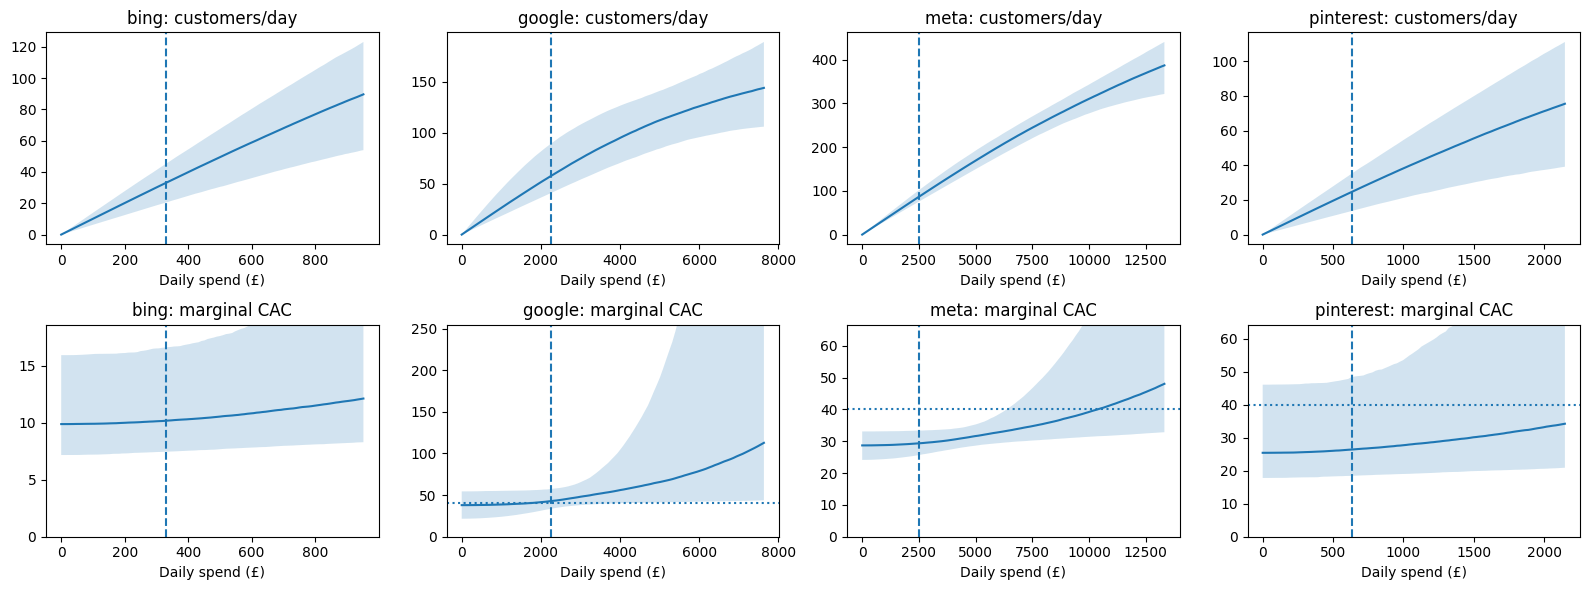

In [14]:
fig, axes = plt.subplots(2, len(CH), figsize=(4 * len(CH), 6))
for i, ch in enumerate(CH):
    xs = np.linspace(0, max(df[ch].quantile(.99) * 1.25, BASE[i] * 1.5), 100)
    resp_draws, cac_draws = [], []
    for x in xs:
        if SATURATION == "logistic":
            z = LAM[:, i] * x / (2 * CS[i])
            r = BETA[:, i] * TS * np.tanh(z)
            der = BETA[:, i] * TS * LAM[:, i] / (2 * CS[i]) / np.cosh(z) ** 2
        else:
            xx = max(x / CS[i], 1e-10)
            a = xx ** SLOPE[:, i]; k = KAPPA[:, i] ** SLOPE[:, i]
            r = BETA[:, i] * TS * a / (k + a)
            der = (BETA[:, i] * TS * SLOPE[:, i] * KAPPA[:, i] ** SLOPE[:, i]
                   * xx ** (SLOPE[:, i] - 1) / (k + a) ** 2) / CS[i]
        resp_draws.append(r)
        cac_draws.append(1 / np.maximum(der, 1e-12))
    resp_draws, cac_draws = np.asarray(resp_draws), np.asarray(cac_draws)
    axes[0, i].plot(xs, np.median(resp_draws, axis=1))
    axes[0, i].fill_between(xs, np.percentile(resp_draws, 5, axis=1), np.percentile(resp_draws, 95, axis=1), alpha=.2)
    axes[0, i].axvline(BASE[i], linestyle="--")
    axes[0, i].set_title(f"{ch}: customers/day")
    axes[0, i].set_xlabel("Daily spend (£)")
    axes[1, i].plot(xs, np.median(cac_draws, axis=1))
    axes[1, i].fill_between(xs, np.percentile(cac_draws, 5, axis=1), np.percentile(cac_draws, 95, axis=1), alpha=.2)
    axes[1, i].axhline(TARGET_CAC, linestyle=":")
    axes[1, i].axvline(BASE[i], linestyle="--")
    axes[1, i].set_ylim(0, min(300, np.nanpercentile(cac_draws, 95)))
    axes[1, i].set_title(f"{ch}: marginal CAC")
    axes[1, i].set_xlabel("Daily spend (£)")
plt.tight_layout()
plt.show()


## Finite 30-day response by channel (what the plans actually buy)
The steady-state curves above describe long-run constant spend. This section answers the brief's question directly for the **30-day window with historical carry-over**: change one channel at a time and report the extra customers and the incremental CAC (`Δ spend / Δ customers`) with its uncertainty.

`P(CAC < £40)` is the share of posterior draws in which the extra customers exceed `Δ spend / 40` (draws with no gain count as failures). A channel is only a candidate to scale if its step stays inside its normal-day P95 spend, because beyond that the model extrapolates.

,channel,step,Δ spend £/30d,Δ customers median,P05,P95,spend/day after,inside normal p95,incremental CAC median £,P(CAC<£40),saving per lost customer £,P(saving/lost > £40)
0,bing,+10%,994.33,97.09,59.49,132.60,364.59,True,10.24,1.00,NaN,NaN
1,bing,+20%,1988.65,193.61,118.63,264.56,397.73,True,10.27,1.00,NaN,NaN
2,bing,-10%,-994.32,-97.73,-133.40,-59.84,298.30,True,NaN,NaN,10.17,0.00
3,google,+10%,6794.86,155.46,116.57,194.49,2491.45,True,43.71,0.27,NaN,NaN
4,google,+20%,13589.72,305.64,230.53,380.31,2717.94,True,44.46,0.22,NaN,NaN
5,google,-10%,-6794.86,-159.67,-205.59,-118.81,2038.46,True,NaN,NaN,42.56,0.65
6,meta,+10%,7528.20,251.66,223.50,283.80,2760.34,True,29.91,1.00,NaN,NaN
7,meta,+20%,15056.41,501.88,446.53,563.78,3011.28,True,30.00,1.00,NaN,NaN
8,meta,-10%,-7528.20,-252.80,-286.81,-223.82,2258.46,True,NaN,NaN,29.78,0.00
9,pinterest,+10%,1903.54,71.22,38.93,102.05,697.97,True,26.73,0.88,NaN,NaN


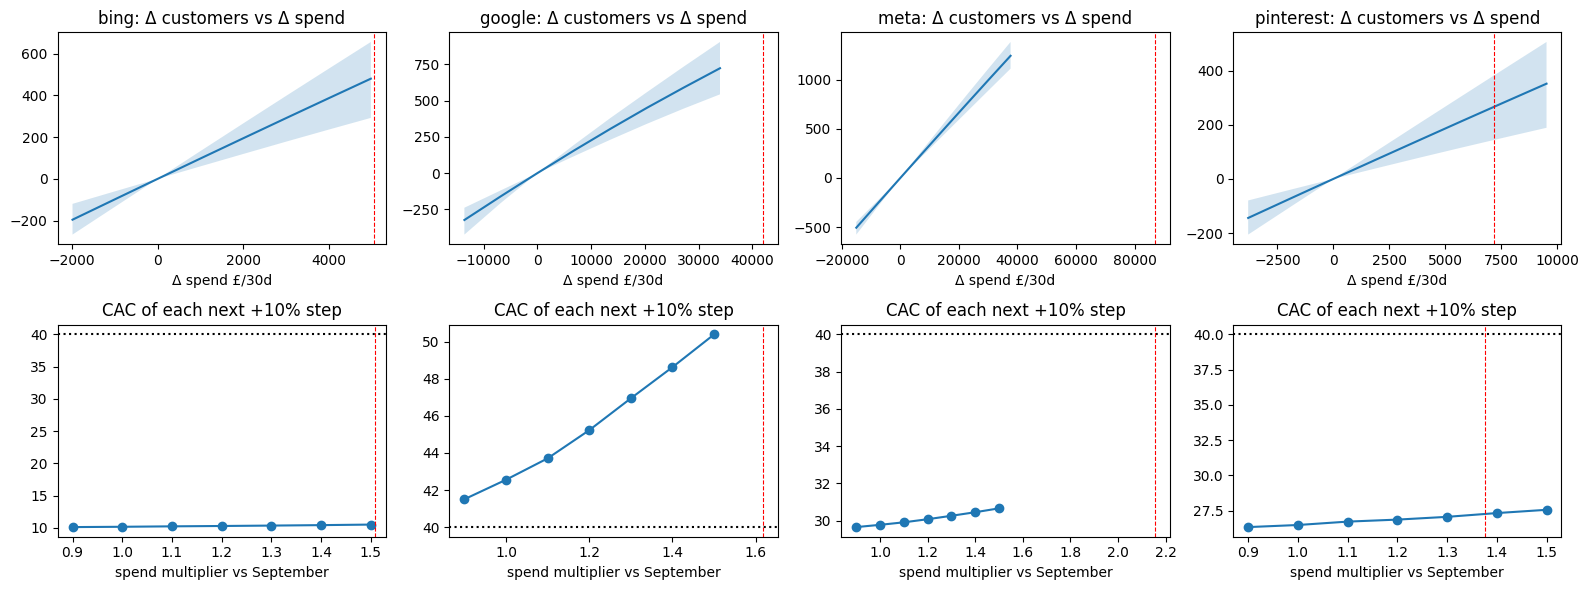

Red dashed line = normal-day P95 spend. Right of it the model extrapolates beyond typical history.


In [15]:
H = 30
BASE_N = ENG.plan(BASE, H)
def step_table(eng, base_n, steps=(1.10, 1.20, 0.90)):
    rows = []
    for i, ch in enumerate(CH):
        for m in steps:
            sp = BASE.copy(); sp[i] *= m
            dN = eng.plan(sp, H) - base_n; dS = (sp[i] - BASE[i]) * H
            r = {"channel": ch, "step": f"{m-1:+.0%}", "Δ spend £/30d": dS, "Δ customers median": np.median(dN),
                 "P05": np.percentile(dN, 5), "P95": np.percentile(dN, 95), "spend/day after": sp[i],
                 "inside normal p95": bool(sp[i] <= P95_HIST[i])}
            if dS > 0:
                c = np.where(dN > 0, dS / np.maximum(dN, 1e-9), np.nan)
                r.update({"incremental CAC median £": np.nanmedian(c), "P(CAC<£40)": float(np.mean(dN > dS / TARGET_CAC))})
            else:
                lost = -dN; c = np.where(lost > 0, -dS / np.maximum(lost, 1e-9), np.nan)
                r.update({"saving per lost customer £": np.nanmedian(c), "P(saving/lost > £40)": float(np.mean(lost < -dS / TARGET_CAC))})
            rows.append(r)
    return pd.DataFrame(rows)
chan_tab = step_table(ENG, BASE_N)
display(chan_tab.round(2))

# крива «приріст клієнтів vs витрати» і крок-за-кроком граничний CAC (скінченне 30-денне вікно)
MULTS = np.round(np.arange(0.8, 1.51, 0.1), 2)
fig, ax = plt.subplots(2, len(CH), figsize=(4 * len(CH), 6))
ladder = {}
for i, ch in enumerate(CH):
    dNs = []
    for m in MULTS:
        sp = BASE.copy(); sp[i] *= m; dNs.append(ENG.plan(sp, H) - BASE_N)
    dNs = np.array(dNs); dSs = (MULTS - 1) * BASE[i] * H; ladder[ch] = (dSs, dNs)
    ax[0, i].plot(dSs, np.median(dNs, 1)); ax[0, i].fill_between(dSs, np.percentile(dNs, 5, 1), np.percentile(dNs, 95, 1), alpha=.2)
    ax[0, i].axvline((P95_HIST[i] / BASE[i] - 1) * BASE[i] * H, c="r", ls="--", lw=.8); ax[0, i].set_title(f"{ch}: Δ customers vs Δ spend"); ax[0, i].set_xlabel("Δ spend £/30d")
    step_cac = [np.nanmedian(np.where((dNs[j + 1] - dNs[j]) > 0, (dSs[j + 1] - dSs[j]) / np.maximum(dNs[j + 1] - dNs[j], 1e-9), np.nan)) for j in range(len(MULTS) - 1)]
    ax[1, i].plot(MULTS[1:], step_cac, "o-"); ax[1, i].axhline(TARGET_CAC, c="k", ls=":"); ax[1, i].axvline(P95_HIST[i] / BASE[i], c="r", ls="--", lw=.8)
    ax[1, i].set_title("CAC of each next +10% step"); ax[1, i].set_xlabel("spend multiplier vs September")
plt.tight_layout(); plt.show()
print("Red dashed line = normal-day P95 spend. Right of it the model extrapolates beyond typical history.")

## Sensitivity: do the channel decisions survive reasonable model changes?
The question is not whether the **total** looks fine but whether each **channel's decision** (scale / hold / reduce at the margin) is stable. Aggregated metrics can hide a channel that sits above £40 while the others are far below it. Each variant below refits the full data, changing one modelling choice at a time: adstock window, seasonality order, saturation form, the channel-effect prior scale (including the value that passes the prior predictive check), default library priors, and the Black Friday indicator set.

Every refit reports its own diagnostics. A variant with divergences, high R-hat or low ESS is **shown but excluded from the stability verdict**, because its numbers are unreliable. Set `RUN_SENSITIVITY = False` to skip (about 2-3 minutes per variant).

In [16]:
import arviz as az
from common import make_mmm
RUN_SENSITIVITY = True
SENS_SAMPLER = dict(chains=2, draws=750, tune=750, target_accept=0.95, cores=max(1, min(2, os.cpu_count() or 1)), random_seed=SEED, progressbar=False)
BF_FEATS = PARAMS["bf_features"]
SENS_SPECS = [  # (label, K, l_max, saturation, beta_sigma, tight_priors, bf_features)
    ("l_max=14",                K_YEARLY, 14,    SATURATION, BETA_SIGMA, True,  BF_FEATS),
    ("l_max=28",                K_YEARLY, 28,    SATURATION, BETA_SIGMA, True,  BF_FEATS),
    ("K=4",                     4,        L_MAX, SATURATION, BETA_SIGMA, True,  BF_FEATS),
    ("K=8",                     8,        L_MAX, SATURATION, BETA_SIGMA, True,  BF_FEATS),
    ("other saturation form",   K_YEARLY, L_MAX, "hill" if SATURATION == "logistic" else "logistic", BETA_SIGMA, True, BF_FEATS),
    ("beta_sigma=0.5",          K_YEARLY, L_MAX, SATURATION, 0.5,        True,  BF_FEATS),
    ("default library priors",  K_YEARLY, L_MAX, SATURATION, 2.0,        False, BF_FEATS),
    ("BF flags: peak+window+bf+cm", K_YEARLY, L_MAX, SATURATION, BETA_SIGMA, True, "peak+window+bf+cm"),
]
def diag(model):
    names = [n for n in ["adstock_alpha", "saturation_lam", "saturation_slope", "saturation_kappa", "saturation_beta", "gamma_control", "gamma_fourier", "y_sigma"] if n in model.idata.posterior]
    s = az.summary(model.idata.posterior, var_names=names)
    return dict(divergences=int(model.idata["sample_stats"]["diverging"].sum()), r_hat_max=float(s["r_hat"].max()), ess_bulk_min=float(s["ess_bulk"].min()))
def decide(p): return "scale" if p >= 0.8 else ("hold/test" if p >= 0.5 else "reduce at margin")
def eval_model(model, label):
    eng = Engine(model); bn = eng.plan(BASE, H); d = diag(model); out = []
    for i, ch in enumerate(CH):
        sp = BASE.copy(); sp[i] *= 1.10; dN = eng.plan(sp, H) - bn; dS = (sp[i] - BASE[i]) * H
        p = float(np.mean(dN > dS / TARGET_CAC))
        out.append(dict(spec=label, channel=ch, dN_median=float(np.median(dN)), icpa_median=float(np.nanmedian(np.where(dN > 0, dS / np.maximum(dN, 1e-9), np.nan))),
                        p_below=p, decision=decide(p), **d, reliable=bool(d["divergences"] <= 10 and d["r_hat_max"] < 1.05 and d["ess_bulk_min"] >= 200)))
    return out
sens_rows = eval_model(mmm, "saved model (base)")
if RUN_SENSITIVITY:
    for label, k, l, sat, bs, tight, bf in SENS_SPECS:
        try:
            ctrl = cfg["controls"] + OPTIONAL_CONTROLS[bf]
            m = make_mmm(CH, ctrl, k, l, sat, bs, tight_priors=tight)
            m.fit(df[["date"] + CH + ctrl], df["new"], **SENS_SAMPLER)
            sens_rows += eval_model(m, label)
        except Exception as e:
            print(f"variant '{label}' failed: {str(e)[:150]}")
sens = pd.DataFrame(sens_rows)
print("Fit diagnostics per specification:")
display(sens.drop_duplicates("spec")[["spec", "divergences", "r_hat_max", "ess_bulk_min", "reliable"]].round(3))
print("\nP(incremental CAC < £40) for a +10% step, by channel and specification:")
display(sens.pivot(index="spec", columns="channel", values="p_below").reindex(sens.spec.unique())[CH].round(2))
print("Median incremental CAC (£) for the same step:")
display(sens.pivot(index="spec", columns="channel", values="icpa_median").reindex(sens.spec.unique())[CH].round(1))

Output()

Output()

Output()

Output()

ERROR:pymc.stats.convergence:There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Output()

... (6 outputs left out)


P(incremental CAC < £40) for a +10% step, by channel and specification:


channel,bing,google,meta,pinterest
spec,,,,
saved model (base),1.00,0.27,1.0,0.88
l_max=14,1.00,0.26,1.0,0.90
l_max=28,1.00,0.26,1.0,0.90
K=4,1.00,0.29,1.0,0.86
K=8,1.00,0.46,1.0,0.85
other saturation form,1.00,0.26,1.0,0.94
beta_sigma=0.5,1.00,0.28,1.0,0.90
default library priors,1.00,0.27,1.0,0.88
BF flags: peak+window+bf+cm,0.93,0.43,1.0,0.94


Median incremental CAC (£) for the same step:


channel,bing,google,meta,pinterest
spec,,,,
saved model (base),10.2,43.7,29.9,26.7
l_max=14,10.2,43.9,30.0,26.7
l_max=28,10.3,43.6,30.0,26.7
K=4,10.8,43.1,30.3,27.4
K=8,8.9,40.5,29.4,28.2
other saturation form,13.6,43.5,29.1,23.2
beta_sigma=0.5,10.2,43.9,29.9,26.9
default library priors,10.3,43.7,30.3,27.2
BF flags: peak+window+bf+cm,21.7,40.8,28.8,27.7


## Decision table (generated from the numbers above)
Rule (agree thresholds with the client): **scale** if `P(CAC<£40) ≥ 0.8` for a +10% step that stays inside the normal-day P95; **hold/test** if 0.5-0.8; **reduce at the margin** if below 0.5. A channel is called **stable** only if the decision is identical in every *reliable* specification.

In [17]:
base_rows = chan_tab[chan_tab.step == "+10%"].set_index("channel")
rel = sens[sens.reliable]
rows = []
for ch in CH:
    p = float(base_rows.loc[ch, "P(CAC<£40)"]); inside = bool(base_rows.loc[ch, "inside normal p95"])
    dec = decide(p) if inside or p < 0.8 else "hold/test (above normal range)"
    ds = rel[rel.channel == ch].decision.unique()
    cap = P95_HIST[CH.index(ch)] / BASE[CH.index(ch)] - 1
    rows.append({"channel": ch, "Sept £/day": BASE[CH.index(ch)], "P(CAC<£40), +10%": p, "incremental CAC median £": base_rows.loc[ch, "incremental CAC median £"],
                 "room to normal p95": f"{cap:+.0%}", "decision (saved model)": dec, "decisions across specs": ", ".join(sorted(ds)),
                 "stable": "yes" if len(ds) == 1 else ("n/a (no reliable spec)" if len(ds) == 0 else "NO")})
decision_table = pd.DataFrame(rows); display(decision_table.round(2))
print("SUMMARY")
for r in rows:
    print(f"- {r['channel']}: {r['decision (saved model)']} (P={r['P(CAC<£40), +10%']:.2f}, incremental CAC ≈ £{r['incremental CAC median £']:.1f}); "
          f"{'stable across reliable specifications' if r['stable']=='yes' else ('stability could not be assessed (no reliable specification)' if r['stable'].startswith('n/a') else 'NOT stable across specifications → test before moving budget')}.")
print("\nIf a channel is not stable, the honest recommendation is a controlled test, not a budget shift.")

,channel,Sept £/day,"P(CAC<£40), +10%",incremental CAC median £,room to normal p95,decision (saved model),decisions across specs,stable
0,bing,331.44,1.00,10.24,+51%,scale,scale,yes
1,google,2264.95,0.27,43.71,+62%,reduce at margin,reduce at margin,yes
2,meta,2509.40,1.00,29.91,+115%,scale,scale,yes
3,pinterest,634.51,0.88,26.73,+38%,scale,scale,yes


SUMMARY
- bing: scale (P=1.00, incremental CAC ≈ £10.2); stable across reliable specifications.
- google: reduce at margin (P=0.27, incremental CAC ≈ £43.7); stable across reliable specifications.
- meta: scale (P=1.00, incremental CAC ≈ £29.9); stable across reliable specifications.
- pinterest: scale (P=0.89, incremental CAC ≈ £26.7); stable across reliable specifications.

If a channel is not stable, the honest recommendation is a controlled test, not a budget shift.


## Decision rule and recommendation

Use a probability-based rule rather than comparing only posterior mean CAC:

- **Scale cautiously:** increase a channel in small steps only when `P(marginal CAC < £40)` is high (suggested operating threshold: at least 80%), the 5th–95th customer range is decision-useful, and the conclusion is stable across sensitivity specifications.
- **Hold / test:** if the probability is between 50% and 80%, or if plausible specifications reverse the ranking, do not make a large permanent change. Run a controlled test.
- **Reduce / reallocate:** consider reducing the *next marginal pound* in a channel when the probability of meeting £40 is low and another channel has consistently better marginal economics. Do not infer that all current spend should be removed.

These thresholds are proposed decision rules, not facts supplied by the dataset. They should be agreed with the client.

## Client testing plan

1. **Pre-register the hypothesis:** e.g. shifting £X/day from the highest marginal-CAC channel to the lowest will increase first-time customers without increasing total spend.
2. **Baseline:** record at least 2–4 weeks of daily spend, new customers, promotions, stock availability, price changes and trading conditions.
3. **Test design:** prefer a geo holdout or matched-market experiment. If unavailable, use a pre-defined switchback schedule with comparable weekdays and avoid overlapping major promotions. Do not change several channels and promotions simultaneously.
4. **Budget:** start with 5–10% of the relevant channel budget, with a fixed maximum loss/spend cap. Keep total spend constant for a reallocation test.
5. **Measurement:** primary outcome = incremental first-time customers; primary efficiency metric = incremental spend / incremental first-time customers. Track total customers and sales as guardrails, not substitutes for the primary outcome.
6. **Review:** weekly operational checks; formal decision after the pre-agreed test duration and adequate sample size. Do not stop early just because one week looks favourable.
7. **Decision:** scale in another 5–10% step only if the experiment supports incremental lift and the uncertainty interval is compatible with CAC below £40. Otherwise hold, reverse, or investigate tracking/seasonality.

The model provides a prior-informed forecast for planning. The experiment is what tests whether the proposed change actually causes additional customers.

In [18]:
# Expected outcome of the proposed test, from the model (for pre-registration, not a guarantee)
cands = decision_table[decision_table["decision (saved model)"].str.startswith("scale")]
pick = (cands if len(cands) else decision_table).sort_values("P(CAC<£40), +10%", ascending=False).iloc[0]["channel"]
i = CH.index(pick); T_DAYS = 28; STEP = 1.10
sp = BASE.copy(); sp[i] *= STEP
dN = ENG.plan(sp, T_DAYS) - ENG.plan(BASE, T_DAYS); dS = (sp[i] - BASE[i]) * T_DAYS
exp = pd.DataFrame({"test channel": [pick], "extra spend £": [dS], "expected extra customers (median)": [np.median(dN)],
                    "5-95% range": [f"{np.percentile(dN,5):.0f} – {np.percentile(dN,95):.0f}"], "expected incremental CAC £": [dS / np.median(dN)],
                    "P(CAC<£40) per model": [np.mean(dN > dS / TARGET_CAC)]})
display(exp.round(2))
print("Decision rule for the test: scale a further step if the measured incremental CAC and its interval are below £40; hold if the interval overlaps £40; reduce or investigate if clearly above, or if the measured lift is outside the model's range above.")

,test channel,extra spend £,expected extra customers (median),5-95% range,expected incremental CAC £,P(CAC<£40) per model
0,meta,7026.32,234.58,209 – 264,29.95,1.0


Decision rule for the test: scale a further step if the measured incremental CAC and its interval are below £40; hold if the interval overlaps £40; reduce or investigate if clearly above, or if the measured lift is outside the model's range above.
